# HypeCheck — test the crowd, not just a tweet
**Veritas AI International High School Hackathon 2026 · AI + Finance**
**Team:** Nathaniel Wong · Aaden Yick · Alastair Chu — Malvern College Hong Kong

**Our user:** a trader who sees many public posts about one memecoin and wonders whether the wording and crowd sentiment deserve forecasting trust. **Input:** a batch of public posts. **Output:** estimated sample sentiment, a next-day direction estimate, and the evidence against simple baselines.

**Bottom line:** this experiment does not demonstrate a forecasting edge. We report that rather than turn a weak model into trading advice.

**Runtime → Run all.** Section 5 visibly trains Model 1; Section 8 makes the exact balanced-weight change and character-ngram trial from ScamCheck. Section 9 runs the trained batch forecast and offers an optional interactive app. Source setup is collapsed; data loading stays short.

**ScamCheck mapping:** original examples → baseline → word model → mistakes → out-of-distribution tests → balanced model → character trial → word explanations → results and limits. Its challenge used team-written modern US-style messages against older UK SMS. We use actual later prices and excluded memecoins, not fictional financial labels. [Exact experiment map](https://github.com/adeviwon/hypecheck/blob/main/docs/scamcheck-pipeline-map.md).

*This project is a prototype and is not financial advice. No complete or live X feed, causal impact or trading skill is claimed. This reused archive is exploratory, not independent confirmation.*

In [1]:
#@title Automatic environment setup
import sys,subprocess,json,hashlib,urllib.request,contextlib,io
from pathlib import Path
IN_COLAB="google.colab" in sys.modules
if IN_COLAB:
    pins=["numpy==2.5.4","pandas==3.1.1","pyarrow==26.0.1","scikit-learn==1.9.1","requests==2.34.2","ipython==9.18.1","ipywidgets==8.1.9","transformers==5.23.0","safetensors==0.8.0"]
    subprocess.run([sys.executable,"-m","pip","install","-q",*pins],check=True)
print("Environment ready; actual Google Colab runtime:",IN_COLAB)

Environment ready; actual Google Colab runtime: False


In [2]:
SETUP_REV='2ce94ac955100ec37968fdfa404e3ae7af8e430b'
BOOTSTRAP={'colab_setup.py': '48e912fec0f69329b2ed93ef5da6cca4890ec191fa6e84367eece7be2a246cb4', 'notebook_support.py': 'e5dd57e29724851b18e5bd2ebfb9b226b4bb5a72be36b4144a51503ab2e01e70'}
SOURCE_REV='690a60d1561a3cabff6e87445cfcb934d32451e2'
SOURCE_FILES={'sample_pipeline.py': '268751cd13f2c47017a96cfb24e5d26ddedd2318748596823bf4be880bdd9605', 'crowd_snapshot.py': 'a32105c5fff454b15619a718a35997da441580866b0054e57e10861115cb134f', 'crowd_app.py': '9b0c527cd800ae3caee7275c0a63fb72c7284d3a3bacc40afdb680e6b40ce081', 'test_sample_pipeline.py': 'ac9c345ed02a4803d428119640b915b5ba410c3ddeb23a3dba398d570ee4cd4a', 'test_crowd_snapshot.py': '79cb9c9983d72e729bf069dc6d253125778d9e2e60ba774499c73ccf7caddb4d', 'test_crowd_app.py': 'ccf94fbc82dff1cd9194eb945db78b8498e433cdb8f93696339a77ce6bb177f1'}
for name,(revision,expected) in {**{n:(SETUP_REV,h) for n,h in BOOTSTRAP.items()},**{n:(SOURCE_REV,h) for n,h in SOURCE_FILES.items()}}.items():
    url=f"https://raw.githubusercontent.com/adeviwon/hypecheck/{revision}/{name}"
    with urllib.request.urlopen(url,timeout=60) as response:payload=response.read()
    if hashlib.sha256(payload).hexdigest()!=expected:raise ValueError("Changed verified file: "+name)
    Path(name).write_bytes(payload)
from colab_setup import prepare
prepare()
import numpy as np,pandas as pd
from IPython.display import display,HTML
from notebook_support import table,accuracy_chart
from sample_pipeline import *
print("Pinned sources and actual market inputs verified; no downloaded forecasts.")

Verified source and market data. Sentiment: verified cache
Pinned sources and actual market inputs verified; no downloaded forecasts.


## 1. Load the data
Real original public X posts and actual daily Binance prices. Frozen FinTwitBERT estimates language sentiment; next-day labels come from the **actual market**, not the sentiment model. The downstream forecast models are trained during this run. Transformers are **not fine-tuned**.

In [3]:
frame,train,later,unseen=dataset()
print(f"Training: {len(train):,} snapshots; later-time test: {len(later):,}; unseen-coin test: {len(unseen):,}.")

Training: 991 snapshots; later-time test: 155; unseen-coin test: 99.


## 2. Look at the data first
Like ScamCheck, read the source examples before fitting. Each row is a same-coin batch observed by a particular UTC cutoff, using the preceding 24 hours. Several snapshots can share one coin-day outcome, so each coin-day gets total weight one. Sentiment describes this supplied archive sample, not all of X.

In [4]:
table(train[["cutoff","date","coin","text","post_count","bullish","bearish","actual_up"]].head(5).assign(text=lambda x:x.text.str.slice(0,350)),"Real historical inputs and market labels")
print("Established training coins:",BASE_COINS)
print("Excluded from supervised training:",NEW_COINS)

Established training coins: ('DOGE', 'SHIB', 'PEPE', 'BONK', 'FLOKI')
Excluded from supervised training: ('WIF', 'TRUMP', 'NEIRO', 'PENGU', 'PNUT', 'TURBO', 'BOME', 'MEME')


cutoff,date,coin,text,post_count,bullish,bearish,actual_up
2024-03-22 06:29:03.335+00:00,2024-03-23 00:00:00+00:00,DOGE,$doge legit best looking major by a mile atm imo,1,0.997797,0.000274,1
2024-03-22 10:29:17.676+00:00,2024-03-23 00:00:00+00:00,DOGE,$doge legit best looking major by a mile atm imo\nBagged some \n\nBeing honest here. I think $doge gonna pull numbers over the coming 3/4 weeks.\n\nTarget 0.45 📸,2,0.987003,0.011575,1
2024-03-22 07:19:03.469+00:00,2024-03-23 00:00:00+00:00,FLOKI,The doge of this cycle should go for the next round anytime now IMO.\n\nAfter consolidation comes continuation.\nInvalidation below the horizontal.\n\n$FLOKI,1,0.864203,0.064860,1
2024-03-31 12:02:52.883+00:00,2024-04-01 00:00:00+00:00,DOGE,$DOGE 12H away from highest weekly close in 123 weeks \n\nProbably nothing,1,0.759038,0.225235,0
2024-03-31 15:02:58.068+00:00,2024-04-01 00:00:00+00:00,DOGE,$DOGE 12H away from highest weekly close in 123 weeks \n\nProbably nothing\n$DOGE to 0.45 real quik\n\n🔮 crystal Ball says,2,0.720262,0.264833,0


## 3. Split into training and test sets
ScamCheck uses stratified random 80/20 with random_state=42. We reproduce that **diagnostic** on historical training data, but do not use its score as forecasting evidence: related snapshots and market dates can appear on both sides.

The primary financial test instead uses earlier calendar dates for training and the final 20% of the price calendar for testing, with a purge. The later-time set uses established coins; the other set uses coins excluded from training. Multi-coin posts mentioning excluded assets are removed from the established training cohort. This is new-to-training data, **not independent confirmation**: the archive was explored before.

In [5]:
from sklearn.model_selection import train_test_split
random_train,random_test=train_test_split(train,test_size=.2,stratify=train.actual_up,random_state=42)
table(pd.DataFrame([{ "set":name,"snapshots":len(d),"coin_days":len(d[["date","coin"]].drop_duplicates()),"dates":d.date.nunique(),"first":str(d.date.min().date()),"last":str(d.date.max().date())} for name,d in [("Training",train),("Later dates",later),("Unseen coins",unseen)]]))
assert train.date.max()+pd.Timedelta(days=1)<min(later.date.min(),unseen.date.min())
print("Random diagnostic shared dates:",len(set(random_train.date)&set(random_test.date)))

Random diagnostic shared dates: 112


set,snapshots,coin_days,dates,first,last
Training,991,556,334,2024-03-23,2025-12-02
Later dates,155,127,91,2026-04-21,2026-10-20
Unseen coins,99,77,57,2026-04-23,2026-10-03


## 4. Baselines: simple rules before AI
ScamCheck always predicts not-spam. We report always-up, training majority/prevalence, coin-only and the previous **completed** UTC-day direction at the snapshot cutoff. No unfinished-day close is allowed.

Report accuracy, precision and recall for UP, confusion matrices and **Brier error** (probability error; lower is better). Methods use identical rows and coin-day weights. A high accuracy alone does not establish forecasting value.

In [6]:
from sklearn.linear_model import LogisticRegression
coin_encoder=encoder(coin_only=True)
coin_model=LogisticRegression(max_iter=1000).fit(coin_encoder.fit_transform(train),train.actual_up,sample_weight=weight(train))
base_models={"Coin only":(coin_encoder,coin_model)}
for label,part in [("Later dates",later),("Unseen coins",unseen)]:
    scores,_=evaluate(base_models,train,part)
    table(pd.DataFrame([{ "method":name,**{k:v for k,v in row.items() if not k.startswith("confusion")}} for name,row in scores.items()]),label)

method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Coin only,0.511811,0.520000,0.406250,0.253185,155,127,91
Always up,0.503937,0.503937,1.000000,0.496063,155,127,91
Training majority,0.496063,0.000000,0.000000,0.503937,155,127,91
Training prevalence,0.496063,0.000000,0.000000,0.250258,155,127,91
Previous completed day,0.472441,0.476923,0.484375,0.527559,155,127,91


method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Coin only,0.558442,0.000000,0.000000,0.248363,99,77,57
Always up,0.441558,0.441558,1.000000,0.558442,99,77,57
Training majority,0.558442,0.000000,0.000000,0.441558,99,77,57
Training prevalence,0.558442,0.000000,0.000000,0.248687,99,77,57
Previous completed day,0.558442,0.500000,0.617647,0.441558,99,77,57


## 5. Model 1: TF-IDF + logistic regression
The same default word TF-IDF and logistic regression as ScamCheck. Our fixed extra features represent estimated batch sentiment and coin identity; they remain unchanged between Model 1 and balanced Model 2. TF-IDF and scaling fit only training data. The label is whether the next complete UTC day closes above its open.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
vec=TfidfVectorizer()
word_encoder=ColumnTransformer([("text",vec,"text"),("numeric",StandardScaler(),SOCIAL),("coin",OneHotEncoder(handle_unknown="ignore"),["coin"])])
X_train=word_encoder.fit_transform(train)
model1=LogisticRegression(max_iter=1000)
model1.fit(X_train,train.actual_up,sample_weight=weight(train))
models={"Model 1":(word_encoder,model1),**base_models}
score1,pred1=evaluate(models,train,later)
table(pd.DataFrame([{ "method":name,**{k:v for k,v in row.items() if not k.startswith("confusion")}} for name,row in score1.items()]),"Model 1 on later dates")
table(pd.DataFrame(score1["Model 1"]["confusion_coin_day_weighted"],columns=["Predicted DOWN/FLAT","Predicted UP"]),"Rows: actual DOWN/FLAT, actual UP; counts are coin-day weighted")

method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.360892,0.373464,0.395833,0.276650,155,127,91
Coin only,0.511811,0.520000,0.406250,0.253185,155,127,91
Always up,0.503937,0.503937,1.000000,0.496063,155,127,91
Training majority,0.496063,0.000000,0.000000,0.503937,155,127,91
Training prevalence,0.496063,0.000000,0.000000,0.250258,155,127,91
Previous completed day,0.472441,0.476923,0.484375,0.527559,155,127,91


Predicted DOWN/FLAT,Predicted UP
20.500000,42.500000
38.666667,25.333333


## 6. Where Model 1 goes wrong
Like the sample, inspect five actual held-out errors. A missed UP and a false-UP forecast are different mistakes. Neither has a universal financial cost: losses depend on returns, fees and execution. These are errors, not fabricated successful demonstrations.

In [8]:
def inspect_errors(part,prep,model,title):
    p=model.predict_proba(prep.transform(part))[:,1]
    bad=part[((p>=.5)!=part.actual_up)].copy()
    bad["estimated_up"]=p[((p>=.5)!=part.actual_up)]
    bad["error_type"]=np.where(bad.actual_up.eq(1),"Missed UP","False UP")
    bad["estimated_language"]=np.where(bad.bullish>bad.bearish,"More bullish","More bearish/neutral")
    saved=export(prep,model)
    def reasons(row):
        explanation=infer(saved,row.to_dict())
        key="toward_up" if row.estimated_up>=.5 else "toward_down"
        return ", ".join(x["word"] for x in explanation[key][:3])
    shown=bad.head(5).copy();shown["actual_word_reasons"]=shown.apply(reasons,axis=1)
    table(shown[["date","coin","error_type","actual_up","estimated_up","actual_word_reasons","text"]].assign(text=lambda x:x.text.str.slice(0,250)),title)
    table(bad.groupby(["error_type","estimated_language"]).size().reset_index(name="raw_snapshot_errors"),"Observed failure patterns; snapshots are dependent")
    print(title+":",len(bad),"wrong of",len(part),"raw snapshots")
inspect_errors(later,word_encoder,model1,"Model 1: later-time errors")

Model 1: later-time errors: 102 wrong of 155 raw snapshots


date,coin,error_type,actual_up,estimated_up,actual_word_reasons,text
2026-04-23 00:00:00+00:00,DOGE,Missed UP,1,0.351569,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,PEPE,Missed UP,1,0.399581,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,PEPE,Missed UP,1,0.419583,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,PEPE,Missed UP,1,0.409850,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,SHIB,Missed UP,1,0.281842,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a


error_type,estimated_language,raw_snapshot_errors
False UP,More bearish/neutral,1
False UP,More bullish,51
Missed UP,More bearish/neutral,15
Missed UP,More bullish,35


## 7. Our addition: later time and another coin market
ScamCheck tests 40 self-written modern US-style messages after training on older UK SMS. We cannot invent future market outcomes, so our analogue uses **every eligible real later-date snapshot** and a separate **unseen-coin-market cohort**, not a 15/25 or 40-case quota. Their prices determine the labels.

We also inspect the top 12 word coefficients, as the sample does. These describe this fitted model, not economic laws or evidence that a word caused a price move.

In [9]:
market_scores,_=evaluate(models,train,unseen)
table(pd.DataFrame([{ "method":name,**{k:v for k,v in row.items() if not k.startswith("confusion")}} for name,row in market_scores.items()]),"Model 1: genuinely excluded coin cohort")
words=np.array(word_encoder.named_transformers_["text"].get_feature_names_out())
coef=model1.coef_[0][word_encoder.output_indices_["text"]]
table(pd.DataFrame({"toward_UP":words[np.argsort(coef)[-12:][::-1]],"toward_DOWN":words[np.argsort(coef)[:12]]}),"Model 1: top word coefficients")

method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.490260,0.419847,0.404412,0.264985,99,77,57
Coin only,0.558442,0.000000,0.000000,0.248363,99,77,57
Always up,0.441558,0.441558,1.000000,0.558442,99,77,57
Training majority,0.558442,0.000000,0.000000,0.441558,99,77,57
Training prevalence,0.558442,0.000000,0.000000,0.248687,99,77,57
Previous completed day,0.558442,0.500000,0.617647,0.441558,99,77,57


toward_UP,toward_DOWN
trend,from
weekly,longed
floki,move
bottom,looking
eth,today
below,early
im,down
strongest,memes
good,follow
next,fresh


## 8. Improvement experiment: balanced class weights
Make **exactly one change**, as ScamCheck does: class_weight=balanced. Keep the vocabulary, numeric features, training rows and target fixed. The purpose is to test class-imbalance behaviour, not assume that catching more UP days improves trading decisions. Report both tests again, whether results improve or worsen.

In [10]:
model2=LogisticRegression(max_iter=1000,class_weight="balanced")
model2.fit(X_train,train.actual_up,sample_weight=weight(train))
models["Model 2"]=(word_encoder,model2)
for label,part in [("Later dates",later),("Unseen coins",unseen)]:
    result,_=evaluate(models,train,part)
    table(pd.DataFrame([{ "method":name,**{k:v for k,v in row.items() if not k.startswith("confusion")}} for name,row in result.items() if name in ["Model 1","Model 2"]]),label+": before and after the one change")
    inspect_errors(part,word_encoder,model2,"Model 2: "+label+" errors")

Model 2: Later dates errors: 101 wrong of 155 raw snapshots
Model 2: Unseen coins errors: 57 wrong of 99 raw snapshots


method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.360892,0.373464,0.395833,0.276650,155,127,91
Model 2,0.367454,0.389140,0.447917,0.276796,155,127,91


date,coin,error_type,actual_up,estimated_up,actual_word_reasons,text
2026-04-23 00:00:00+00:00,DOGE,Missed UP,1,0.361756,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,PEPE,Missed UP,1,0.410392,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,PEPE,Missed UP,1,0.431144,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,PEPE,Missed UP,1,0.421386,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a
2026-04-23 00:00:00+00:00,SHIB,Missed UP,1,0.290517,"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA\n\n People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell it within minutes or seconds. It's time holders win again.\n\nMAGA is a breath of fresh a


error_type,estimated_language,raw_snapshot_errors
False UP,More bearish/neutral,1
False UP,More bullish,54
Missed UP,More bearish/neutral,14
Missed UP,More bullish,32


method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.490260,0.419847,0.404412,0.264985,99,77,57
Model 2,0.438312,0.386503,0.463235,0.266244,99,77,57


date,coin,error_type,actual_up,estimated_up,actual_word_reasons,text
2026-04-23 00:00:00+00:00,NEIRO,False UP,0,0.523884,"soon, god",$Neiro & $BERT god candles soon
2026-04-25 00:00:00+00:00,PENGU,Missed UP,1,0.408812,"today, 25, yesterday",Coffee and charts with @get_truenorth day 2.\n\nHit a winner yesterday on $PENGU and today I'm shifting some focus to $ZEC. \n\nPrompting to refine a set up and be more aggressive in upside targeting.\n\n25 more spots open for today only: https://app.true-
2026-04-25 00:00:00+00:00,TRUMP,False UP,0,0.579584,"trump, april",WHITE HOUSE CONFIRMS TRUMP WILL ADDRESS $TRUMP MEMECOIN HOLDERS AT MAR-A-LAGO GALA ON APRIL 25
2026-04-26 00:00:00+00:00,TRUMP,Missed UP,1,0.406892,,We are winning so much mister president \n\n$TRUMP\n\nLmao what a crime show
2026-04-28 00:00:00+00:00,PENGU,False UP,0,0.580934,"time, think, market",What do you think happens to $PENGU when the NFT market rips to new all time highs?\n\nFlightless birds will once again fly.\n$BERT and $PENGU \n\nidentical patterns and breakouts before and even now


error_type,estimated_language,raw_snapshot_errors
False UP,More bearish/neutral,5
False UP,More bullish,28
Missed UP,More bearish/neutral,9
Missed UP,More bullish,15


### One alternative we tried: character n-grams
Reproduce the sample trial: char_wb, ngrams (2,5), sublinear TF, balanced logistic regression and C=10. Keep the same sentiment and coin features. Show all results. The word-balanced model is predeclared as the readable demo, **not selected because it wins on test accuracy**. Looking at these reused tests cannot establish an independent improvement.

In [11]:
cvec=TfidfVectorizer(analyzer="char_wb",ngram_range=(2,5),sublinear_tf=True)
char_encoder=ColumnTransformer([("text",cvec,"text"),("numeric",StandardScaler(),SOCIAL),("coin",OneHotEncoder(handle_unknown="ignore"),["coin"])])
cmodel=LogisticRegression(max_iter=1000,class_weight="balanced",C=10)
cmodel.fit(char_encoder.fit_transform(train),train.actual_up,sample_weight=weight(train))
models["Character trial"]=(char_encoder,cmodel)
def use_visible_models(data):
    return models if data.index.equals(train.index) else fit_models(data)
with contextlib.redirect_stdout(io.StringIO()):
    artifact,report=run_experiment(trainer=use_visible_models)
for name in ["later_time","unseen_coin_market"]:
    table(pd.DataFrame([{ "model":m,**{k:v for k,v in row.items() if not k.startswith("confusion")}} for m,row in report["tests"][name].items()]),name)
print("Random 80/20 is diagnostic only:",report["random_80_20_diagnostic"]["status"])
table(pd.DataFrame([{ "model":m,"diagnostic_accuracy":v["accuracy"]} for m,v in report["random_80_20_diagnostic"]["metrics"].items()]),"Do not confuse this with future forecasting")

Random 80/20 is diagnostic only: Exact sample split reproduced on historical training subset only; NOT a valid forecasting headline because shared dates/outcomes can leak.


model,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.360892,0.373464,0.395833,0.276650,155,127,91
Coin only,0.511811,0.520000,0.406250,0.253185,155,127,91
Model 2,0.367454,0.389140,0.447917,0.276796,155,127,91
Character trial,0.400262,0.407595,0.419271,0.341824,155,127,91
Always up,0.503937,0.503937,1.000000,0.496063,155,127,91
Training majority,0.496063,0.000000,0.000000,0.503937,155,127,91
Training prevalence,0.496063,0.000000,0.000000,0.250258,155,127,91
Previous completed day,0.472441,0.476923,0.484375,0.527559,155,127,91


model,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.490260,0.419847,0.404412,0.264985,99,77,57
Coin only,0.558442,0.000000,0.000000,0.248363,99,77,57
Model 2,0.438312,0.386503,0.463235,0.266244,99,77,57
Character trial,0.451299,0.398773,0.477941,0.297015,99,77,57
Always up,0.441558,0.441558,1.000000,0.558442,99,77,57
Training majority,0.558442,0.000000,0.000000,0.441558,99,77,57
Training prevalence,0.558442,0.000000,0.000000,0.248687,99,77,57
Previous completed day,0.558442,0.500000,0.617647,0.441558,99,77,57


model,diagnostic_accuracy
Model 1,0.664596
Model 2,0.667702
Character trial,0.739130
Coin only,0.527950
Always up,0.478261
Training majority,0.521739
Training prevalence,0.521739
Previous completed day,0.440994


## 9. The demo: explain a batch forecast
ScamCheck explains using TF-IDF × coefficient. We do the same for words in the supplied batch and keep sentiment/coin contributions separate. The first demonstration uses the **first eligible held-out historical snapshot**, transported as quoted CSV to preserve blank lines inside original posts. It is an illustration, not an independent test.

The three panels distinguish estimated language sentiment, a price-direction model estimate, and whether the evidence supports trusting it. No causal price-impact estimate or guaranteed return is shown.

In [12]:
from crowd_app import panels,build_app
example=later.iloc[0]
result=batch_check(historical_csv(example),example.coin,example.cutoff.isoformat(),artifact=artifact,input_format="csv")
for content in panels(result,report):display(HTML(content))
print("Historical reveal — actual next-day direction:","UP" if example.actual_up else "DOWN / FLAT")
table(pd.DataFrame(result["toward_up"]+result["toward_down"]),"Actual word × TF-IDF contributions (logit units)")

Historical reveal — actual next-day direction: UP


word,logit_contribution
forward,0.036360
double,0.031709
created,0.028865
especially,0.026646
holding,0.024437
pepe,-0.053815
moving,-0.051019
narrative,-0.041521
middle,-0.026624
bags,-0.025760


### Optional interactive app
Set RUN_APP=True and run the next cell. Paste public posts separated by blank lines, or CSV with a text column; choose a coin and click Analyse batch. Use CSV if an individual post itself contains blank lines. New text runs actual pinned FinTwitBERT inference, then the fitted forecast model—no phrase-list fallback.

Blank cutoff means actual submission time in UTC; exact next-day dates are displayed. A pasted old post is analysed at that submission time, not silently backtested. Supplied timestamps can be checked for window consistency, but their authenticity and complete platform coverage are not independently verified. No live X feed is connected.

In [13]:
#@title Open the real batch input app
RUN_APP=False #@param {type:"boolean"}
if RUN_APP:
    ui,app_state,controls=build_app(artifact)
    display(ui)
else:
    print("Optional app is off so Run all finishes. Set RUN_APP=True to enter your batch.")

Optional app is off so Run all finishes. Set RUN_APP=True to enter your batch.


## 10. Results summary
Compare the same rows before and after balanced weights, plus the character alternative. UP precision/recall expose the tradeoff that accuracy alone hides. Full confusion matrices and test support are saved in the report. The chart uses a full 0–100% axis.

Paired date-block accuracy differences vs coin-only: {'later_time': {'mean': -0.1443569553805774, 'interval95': [-0.23759155912103244, -0.03939410016977936], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}, 'unseen_coin_market': {'mean': -0.12012987012987013, 'interval95': [-0.24142359470949457, 0.014947808426223293], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}}


test,model,accuracy,UP_precision,UP_recall,Brier
later_time,Model 1,0.360892,0.373464,0.395833,0.276650
later_time,Coin only,0.511811,0.520000,0.406250,0.253185
later_time,Model 2,0.367454,0.389140,0.447917,0.276796
later_time,Character trial,0.400262,0.407595,0.419271,0.341824
later_time,Always up,0.503937,0.503937,1.000000,0.496063
later_time,Training majority,0.496063,0.000000,0.000000,0.503937
later_time,Training prevalence,0.496063,0.000000,0.000000,0.250258
later_time,Previous completed day,0.472441,0.476923,0.484375,0.527559
unseen_coin_market,Model 1,0.490260,0.419847,0.404412,0.264985
unseen_coin_market,Coin only,0.558442,0.000000,0.000000,0.248363


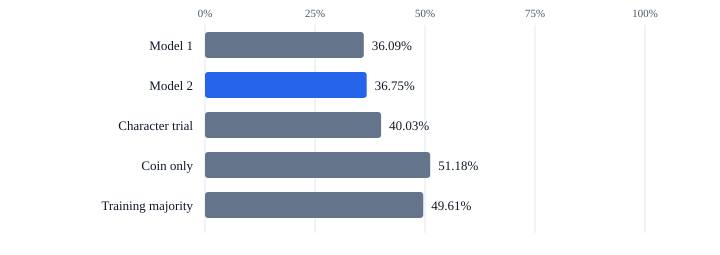

In [14]:
table(pd.DataFrame([{ "test":test_name,"model":name,"accuracy":row["accuracy"],"UP_precision":row["up_precision"],"UP_recall":row["up_recall"],"Brier":row["brier"]} for test_name,test in report["tests"].items() for name,row in test.items()]),"Complete measured comparison")
accuracy_chart({"primary_model":"Model 2","metrics":report["tests"]["later_time"]},["Model 1","Model 2","Character trial","Coin only","Training majority"])
print("Paired date-block accuracy differences vs coin-only:",report["paired_accuracy_vs_coin_only"])

## 11. Limitations and next steps
- This is a sparse archive, not every public post about a coin. Estimated sample sentiment is not validated full-population sentiment.
- The later-time and unseen-coin experiments use actual prices but reused dates; they are exploratory, not independent confirmation. Small per-coin samples limit conclusions.
- Balanced weights may increase UP recall while worsening false alarms or accuracy. They do not create trading skill. The character trial can overfit and gives less readable fragments.
- Probabilities are not independently calibrated. No profitability, fees/slippage, causal effect or useful return-magnitude forecast is established. Do not invert a losing model after seeing test labels and call that a new validated strategy.
- Next: gather a genuinely new timestamped public sample, freeze this protocol and evaluate prospectively; test whether users understand the evidence warnings.

**Investor boundary:** this prototype does not justify trading because a batch sounds bullish or the model predicts UP. Its useful result is demonstrating how apparent text-based confidence can fail a fair future-market test.

In [15]:
for filename in ["test_crowd_snapshot.py","test_sample_pipeline.py","test_crowd_app.py"]:
    completed=subprocess.run([sys.executable,filename],text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
    print(completed.stdout);completed.check_returncode()
print("Saved safe JSON models and genuine outputs. Actual Google Colab runtime:",IN_COLAB)

.............
----------------------------------------------------------------------
Ran 13 tests in 0.001s

OK

..........
----------------------------------------------------------------------
Ran 10 tests in 32.076s

OK

..
----------------------------------------------------------------------
Ran 2 tests in 23.539s

OK

Saved safe JSON models and genuine outputs. Actual Google Colab runtime: False


## Sources
- [financial-tweets-crypto](https://huggingface.co/datasets/StephanAkkerman/financial-tweets-crypto), pinned revision and source hash in pipeline.py.
- [FinTwitBERT sentiment](https://huggingface.co/StephanAkkerman/FinTwitBERT-sentiment), pinned safe weights; scores are model estimates, not human gold labels.
- Actual Binance spot daily bars, frozen and hash-checked. [Market-data documentation](https://github.com/binance/binance-spot-api-docs/blob/master/rest-api.md#klinecandlestick-data).
- scikit-learn, PyTorch, Transformers, safetensors, NumPy, pandas, PyArrow, IPython and ipywidgets.
- Veritas AI ScamCheck sample notebook and Finance brief: same experiment sequence with documented adaptations for temporal finance data. [Exact mapping](https://github.com/adeviwon/hypecheck/blob/main/docs/scamcheck-pipeline-map.md).
- Hermes Agent/OpenAI coding assistance. The team must understand and explain the work. Third-party data/model terms remain applicable.

*This project is a prototype and is not financial advice.*